In [1]:
# 3D. Detect the faults in Sensor Data from Machinery (NASA Turbofan Engine Dataset)
# using Autoencoder and build the model by using the following steps:
# • Dataset: The dataset contains sensor readings from turbofan engines with labels
# indicating whether a reading is faulty.
# • Goal: Detect machinery faults by training an autoencoder on sensor data from healthy
# engines.
# Steps:
# • Preprocess data by scaling sensor readings.
# • Use an LSTM-based autoencoder (to capture sequential data) to learn patterns in
# normal sensor readings.
# • Calculate reconstruction error for test data, with a threshold to classify high-error
# instances as faults.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report

In [2]:
data = pd.read_csv("/Users/aayushagarwal/Downloads/LP IV Updated Datasets/AutoEncoder/NASA Turbofan ENgine/NASA TurboFan Engine.csv")
print(data)

       unit  cycle  setting1  setting2  setting3  sensor1  sensor2  sensor3  \
0         1      1   -0.0007   -0.0004     100.0   518.67   641.82  1589.70   
1         1      2    0.0019   -0.0003     100.0   518.67   642.15  1591.82   
2         1      3   -0.0043    0.0003     100.0   518.67   642.35  1587.99   
3         1      4    0.0007    0.0000     100.0   518.67   642.35  1582.79   
4         1      5   -0.0019   -0.0002     100.0   518.67   642.37  1582.85   
...     ...    ...       ...       ...       ...      ...      ...      ...   
20626   100    196   -0.0004   -0.0003     100.0   518.67   643.49  1597.98   
20627   100    197   -0.0016   -0.0005     100.0   518.67   643.54  1604.50   
20628   100    198    0.0004    0.0000     100.0   518.67   643.42  1602.46   
20629   100    199   -0.0011    0.0003     100.0   518.67   643.23  1605.26   
20630   100    200   -0.0032   -0.0005     100.0   518.67   643.85  1600.38   

       sensor4  sensor5  ...  sensor14  sensor15  s

In [3]:
# RUL and Fault_Label are not inputs, otherwise the label leaks into the features
features = [col for col in data.columns if col.startswith(("setting", "sensor"))]

X = data[features].values
y = data["Fault_Label"].values

x_train , x_test , y_train , y_test = train_test_split(X , y , test_size=0.2 , random_state=42)

In [4]:
# Normalize : fit the scaler on training data only
scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

In [5]:
# No time windows : each reading is treated as a sequence of 1 timestep
x_train = x_train.reshape(-1 , 1 , x_train.shape[1])
x_test = x_test.reshape(-1 , 1 , x_test.shape[1])

# Train only on healthy readings
x_train = x_train[y_train == 0]

print(x_train.shape , x_test.shape)

(13988, 1, 24) (4127, 1, 24)


In [6]:
class LSTMAutoencoder(keras.Model):
    def __init__(self , timesteps , n_features):
        super().__init__()

        self.encoder = keras.Sequential([
            keras.layers.LSTM(32 , return_sequences=True),
            keras.layers.LSTM(8),
        ])

        self.decoder = keras.Sequential([
            keras.layers.RepeatVector(timesteps),
            keras.layers.LSTM(8 , return_sequences=True),
            keras.layers.LSTM(32 , return_sequences=True),
            keras.layers.TimeDistributed(keras.layers.Dense(n_features)),
        ])

    def call(self , inputs):
        return self.decoder(self.encoder(inputs))

model = LSTMAutoencoder(x_train.shape[1] , x_train.shape[2])

In [7]:
model.compile(optimizer=keras.optimizers.Adam(3e-3) , loss="mse")

In [8]:
history = model.fit(x_train , x_train , epochs=40 , batch_size=64 , validation_split=0.1)

Epoch 1/40
197/197 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.3380 - val_loss: 0.2730
Epoch 2/40
197/197 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.2432 - val_loss: 0.2022
Epoch 3/40
197/197 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.1848 - val_loss: 0.1635
Epoch 4/40
197/197 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.1608 - val_loss: 0.1558
Epoch 5/40
197/197 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.1303 - val_loss: 0.1204
Epoch 6/40
197/197 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.1214 - val_loss: 0.1198
Epoch 7/40
197/197 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.1206 - val_loss: 0.1191
Epoch 8/40
197/197 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.1200 - val_loss: 0.1180
Epoch 9/40
197/197 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.1123 - val_loss: 0.1054
Epoch 10/40
197/197 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.1054 - val_loss: 0.1028
Epoch 11/40
197/197 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0962 - val_loss: 0.0897
Epoch 12/40
197/197 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step

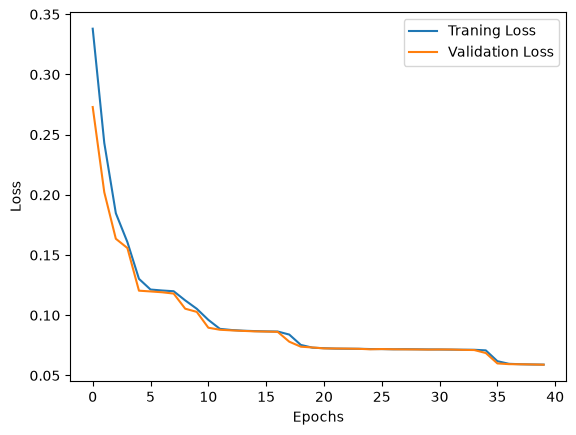

In [9]:
plt.plot(history.history["loss"] , label = "Traning Loss")
plt.plot(history.history["val_loss"] , label = "Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

In [10]:
def get_errors(original , reconstructed):
    return np.mean(
        (original - reconstructed) ** 2 , axis = (1 , 2)
    )

In [11]:
train_errors = get_errors(x_train , model.predict(x_train , verbose=0))

In [12]:
threshold = np.percentile(train_errors , 95)
print(threshold)

0.11811692603009025


In [13]:
test_errors = get_errors(x_test , model.predict(x_test , verbose=0))
predictions = np.where(test_errors > threshold , 1 , 0)

In [14]:
print(classification_report(y_test , predictions , target_names=["Normal" , "Fault"]))

              precision    recall  f1-score   support

      Normal       0.88      0.95      0.91      3543
       Fault       0.38      0.20      0.26       584

    accuracy                           0.84      4127
   macro avg       0.63      0.57      0.58      4127
weighted avg       0.81      0.84      0.82      4127

